# CSIS 4495 002 Applied Research Project
- Student Name: Liqin Shi
- Student ID: 300431612

## 1. Data Loading and Initial Inspection

In [1]:
# Data handling
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt

# Split data into training and testing sets
from sklearn.model_selection import train_test_split

# Preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

In [2]:
df = pd.read_sas("../LocalData/LLCP2025.XPT", format="xport")

In [3]:
# Load the official CDC BRFSS 2025 data
df = pd.read_csv("../LocalData/BRFSS2025.csv")

# Basic dataset information
print("Shape:", df.shape)
display(df.head())

Shape: (356158, 283)


,_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,_PSU,CTELENM1,...,_VEGRES1,_FRUTSU1,_VEGESU1,_FRTLT1A,_VEGLT1A,_FRT16A,_VEG23A,_FRUITE1,_VEGETE1,_AIDTST4
0,1.0,1.0,b'04072025',b'04',b'07',b'2025',1100.0,b'2025000001',2.025000e+09,1.0,...,1.0,100.0,130.0,1.0,1.0,1.0,1.0,5.397605e-79,5.397605e-79,1.0
1,1.0,1.0,b'04072025',b'04',b'07',b'2025',1100.0,b'2025000002',2.025000e+09,1.0,...,1.0,107.0,145.0,1.0,1.0,1.0,1.0,5.397605e-79,5.397605e-79,2.0
2,1.0,1.0,b'04042025',b'04',b'04',b'2025',1100.0,b'2025000003',2.025000e+09,1.0,...,1.0,72.0,144.0,2.0,1.0,1.0,1.0,5.397605e-79,5.397605e-79,2.0
3,1.0,1.0,b'04082025',b'04',b'08',b'2025',1100.0,b'2025000004',2.025000e+09,1.0,...,1.0,300.0,63.0,1.0,2.0,1.0,1.0,5.397605e-79,5.397605e-79,2.0
4,1.0,1.0,b'04082025',b'04',b'08',b'2025',1100.0,b'2025000005',2.025000e+09,1.0,...,1.0,100.0,700.0,1.0,1.0,1.0,1.0,5.397605e-79,5.397605e-79,2.0


In [4]:
# Display all column names
print(df.columns.tolist())

['_STATE', 'FMONTH', 'IDATE', 'IMONTH', 'IDAY', 'IYEAR', 'DISPCODE', 'SEQNO', '_PSU', 'CTELENM1', 'PVTRESD1', 'COLGHOUS', 'STATERE1', 'CELPHON1', 'LADULT1', 'NUMADULT', 'RESPSLC1', 'LANDSEX4', 'SAFETIME', 'CTELNUM1', 'CELLFON5', 'CADULT1', 'CELLSEX4', 'PVTRESD3', 'CCLGHOUS', 'CSTATE1', 'LANDLINE', 'HHADULT', 'SEXVAR', 'GENHLTH', 'PHYSHLTH', 'MENTHLTH', 'POORHLTH', 'PRIMINS2', 'PERSDOC3', 'MEDCOST1', 'CHECKUP1', 'EXERANY2', 'BPHIGH6', 'BPMEDS1', 'CHOLCHK3', 'TOLDHI3', 'CHOLMED3', 'CVDINFR4', 'CVDCRHD4', 'CVDSTRK3', 'ASTHMA3', 'ASTHNOW', 'CHCSCNC1', 'CHCOCNC1', 'CHCCOPD3', 'ADDEPEV3', 'CHCKDNY2', 'HAVARTH4', 'DIABETE4', 'DIABAGE4', 'MARITAL', 'EDUCA', 'RENTHOM1', 'NUMHHOL4', 'NUMPHON4', 'CPDEMO1C', 'VETERAN3', 'EMPLOY1', 'CHILDREN', 'INCOME3', 'PREGNANT', 'WEIGHT2', 'HEIGHT3', 'DEAF', 'BLIND', 'DECIDE', 'DIFFWALK', 'DIFFDRES', 'DIFFALON', 'SLEPTIM1', 'SMOKE100', 'SMOKDAY2', 'USENOW3', 'ECIGNOW3', 'ALCDAY4', 'AVEDRNK4', 'DRNK3GE5', 'MAXDRNKS', 'FLUSHOT7', 'FLSHTMY3', 'PNEUVAC4', 'TETANUS1

In [5]:
missing = df.isnull().sum().sort_values(ascending=False)

display(missing.head(30))

ICFQSTVR    356158
COLGHOUS    356153
CSRVCTL2    355628
CCLGHOUS    355147
CSRVINST    354093
HPVADSHT    353642
NOBCUSE9    353591
CSRVCLIN    353410
CSRVDEIN    353406
CSRVINSR    353403
CSRVRTRN    353396
CSRVSUM     353392
CSRVDOC1    353388
CASTHNO2    353217
NUMPHON4    352346
USEMRJN4    352330
PSASUGS1    351945
PCPSARS2    351938
PSATIME1    351933
MENTECIG    351664
CSRVTRT3    351426
LOADULK2    350566
CSRVPAIN    350483
CNCRTYP2    348970
CNCRAGE     348960
PCSTALK2    348844
PSATEST1    348802
CNCRDIFF    348772
MENTCIGS    348324
MARJOTHR    347202
dtype: int64

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 356158 entries, 0 to 356157
Columns: 283 entries, _STATE to _AIDTST4
dtypes: float64(278), object(5)
memory usage: 769.0+ MB


In [7]:
missing = df.isnull().sum().sort_values(ascending=False)

display(missing)

ICFQSTVR    356158
COLGHOUS    356153
CSRVCTL2    355628
CCLGHOUS    355147
CSRVINST    354093
             ...  
_AGE65YR         0
_AGE80           0
_AGE_G           0
_RFBMI5          0
_STATE           0
Length: 283, dtype: int64

In [8]:
# Calculate missing percentage for each column
missing_pct = df.isnull().mean() * 100

# Group columns by missing percentage
print("Total columns:", len(df.columns))
print("No missing values:", (missing_pct == 0).sum())
print("0–10% missing:", ((missing_pct > 0) & (missing_pct <= 10)).sum())
print("10–30% missing:", ((missing_pct > 10) & (missing_pct <= 30)).sum())
print("30–50% missing:", ((missing_pct > 30) & (missing_pct <= 50)).sum())
print("50–80% missing:", ((missing_pct > 50) & (missing_pct <= 80)).sum())
print("80–100% missing:", ((missing_pct > 80) & (missing_pct <= 100)).sum())

Total columns: 283
No missing values: 59
0–10% missing: 62
10–30% missing: 25
30–50% missing: 1
50–80% missing: 28
80–100% missing: 108


## 2. Feature Selection and Data Cleaning

In [9]:
# Search for candidate variables related to diabetes risk factors

keywords = [
    "DIAB", "AGE", "SEX", "RACE", "EDU", "INCOME",
    "BMI", "BPHIGH", "CHOL", "CVD",
    "STROKE", "EXER", "PHYS", "SMOK",
    "ALCO", "FRUIT", "VEG",
    "GENHLTH", "MENTHLTH", "PHYSHLTH",
    "DIFF", "HLTHPLN", "COST", "CHECK"
]

for keyword in keywords:
    matches = [col for col in df.columns if keyword in col.upper()]
    print(f"\n{keyword}:")
    print(matches)


DIAB:
['DIABETE4', 'DIABAGE4', 'PDIABTS1', 'PREDIAB2', 'DIABTYPE', 'DIABEYE1', 'DIABEDU1']

AGE:
['DIABAGE4', 'CNCRAGE', 'CAGEG', '_AGEG5YR', '_AGE65YR', '_AGE80', '_AGE_G']

SEX:
['LANDSEX4', 'CELLSEX4', 'SEXVAR', 'ACEHVSEX', 'HADSEX', '_SEX']

RACE:
['_IMPRACE', '_CRACE1', '_MRACE1', '_RACE', '_RACEG21', '_RACEGR3', '_RACEPRV']

EDU:
['EDUCA', 'DIABEDU1', 'ARTHEDU', '_EDUCAG']

INCOME:
['INCOME3']

BMI:
['_BMI5', '_BMI5CAT', '_RFBMI5']

BPHIGH:
['BPHIGH6']

CHOL:
['CHOLCHK3', 'CHOLMED3', '_CHOLCH3', '_RFCHOL3']

CVD:
['CVDINFR4', 'CVDCRHD4', 'CVDSTRK3']

STROKE:
[]

EXER:
['EXERANY2', 'ARTHEXER']

PHYS:
['PHYSHLTH', '_PHYS14D']

SMOK:
['SMOKE100', 'SMOKDAY2', 'MARJSMOK', '_SMOKER3', '_RFSMOK3']

ALCO:
['_DUALCOR']

FRUIT:
['FRUIT2', 'FRUITJU2', '_FRUITE1']

VEG:
['VEGETAB2', 'VEGEDA2_', '_MISVEG1', '_VEGRES1', '_VEGESU1', '_VEGLT1A', '_VEG23A', '_VEGETE1']

GENHLTH:
['GENHLTH']

MENTHLTH:
['MENTHLTH']

PHYSHLTH:
['PHYSHLTH']

DIFF:
['DIFFWALK', 'DIFFDRES', 'DIFFALON', 'CNCRDIFF']

H

### Initial Feature Selection – BRFSS 2025
Candidate variables were reviewed using the CDC BRFSS 2025 codebook. Variables were selected based on their potential relevance to diabetes and prediabetes, while retaining additional candidates for later exploratory analysis and feature selection. Final features will be determined after data cleaning, EDA, missing-value analysis, and feature evaluation.

### 2.1 Target Variable Preparation

In [10]:
# Check the original distribution of the diabetes target variable
df['DIABETE4'].value_counts(dropna=False).sort_index()

DIABETE4
1.0     51827
2.0      2671
3.0    290712
4.0     10166
7.0       580
9.0       196
NaN         6
Name: count, dtype: int64

In [11]:
# Check percentages
df['DIABETE4'].value_counts(
    dropna=False,
    normalize=True
).sort_index() * 100

DIABETE4
1.0    14.551688
2.0     0.749948
3.0    81.624448
4.0     2.854351
7.0     0.162849
9.0     0.055032
NaN     0.001685
Name: proportion, dtype: float64

In [12]:
# Create a clean three-class diabetes target variable
diabetes_map = {
    1: 'Diabetes',
    3: 'No Diabetes',
    4: 'Prediabetes'
}

df['Diabetes_Status'] = df['DIABETE4'].map(diabetes_map)

# Check the cleaned target distribution
df['Diabetes_Status'].value_counts(dropna=False)

Diabetes_Status
No Diabetes    290712
Diabetes        51827
Prediabetes     10166
NaN              3453
Name: count, dtype: int64

## 3. Exploratory Data Analysis (EDA)

### 3.1 Demographic Variables

In [13]:
# Keep the CDC age variable for modeling
df['Age'] = df['_AGE80']

# Main age groups aligned with the National Diabetes Statistics Report.
# This grouping allows direct comparison with the national report:
# 18–44, 45–64, and 65 years or older.
df['Age_Group'] = pd.cut(
    df['Age'],
    bins=[17, 44, 64, float('inf')],
    labels=['18-44', '45-64', '65+']
)

# Create more detailed age groups for exploratory analysis.
# Broader groups are used below age 50 for concise comparison,
# while 5-year groups from age 50 onward provide more detail.
df['Age_Group_Detailed'] = pd.cut(
    df['Age'],
    bins=[17, 39, 49, 54, 59, 64, 69, 74, 79, float('inf')],
    labels=[
        '18-39',
        '40-49',
        '50-54',
        '55-59',
        '60-64',
        '65-69',
        '70-74',
        '75-79',
        '80+'
    ]
)

# Check the distributions
print("National report age groups:")
print(df['Age_Group'].value_counts(dropna=False).sort_index())

print("\nDetailed age groups:")
print(df['Age_Group_Detailed'].value_counts(dropna=False).sort_index())

National report age groups:
Age_Group
18-44    105537
45-64    108396
65+      142225
Name: count, dtype: int64

Detailed age groups:
Age_Group_Detailed
18-39    82218
40-49    45997
50-54    25035
55-59    27901
60-64    32782
65-69    37194
70-74    36613
75-79    31526
80+      36892
Name: count, dtype: int64


In [14]:
# Check the original distribution of sex
print(df['_SEX'].value_counts(dropna=False).sort_index())

print("\nPercentage:")
print(
    df['_SEX']
    .value_counts(normalize=True, dropna=False)
    .sort_index() * 100
)

_SEX
1.0    168462
2.0    187696
Name: count, dtype: int64

Percentage:
_SEX
1.0    47.299794
2.0    52.700206
Name: proportion, dtype: float64


In [15]:
# Create a readable sex variable
sex_map = {
    1: 'Male',
    2: 'Female'
}

df['Sex'] = df['_SEX'].map(sex_map)

# Check the cleaned distribution
print(df['Sex'].value_counts(dropna=False))

print("\nPercentage:")
print(
    df['Sex']
    .value_counts(normalize=True, dropna=False) * 100
)

Sex
Female    187696
Male      168462
Name: count, dtype: int64

Percentage:
Sex
Female    52.700206
Male      47.299794
Name: proportion, dtype: float64


In [16]:
# Compare diabetes status by sex
sex_diabetes = pd.crosstab(
    df['Sex'],
    df['Diabetes_Status'],
    normalize='index'
) * 100

display(sex_diabetes.round(2))

Diabetes_Status,Diabetes,No Diabetes,Prediabetes
Sex,,,
Female,14.14,82.81,3.05
Male,15.31,82.00,2.70


### Sex Analysis  
In the BRFSS 2025 sample, males had a slightly higher proportion of diabetes (15.31%) than females (14.14%), while females had a slightly higher proportion of prediabetes (3.05%) than males (2.70%).

In [17]:
# Compare diabetes status by National Report age groups
age_diabetes_national = pd.crosstab(
    df['Age_Group'],
    df['Diabetes_Status'],
    normalize='index'
) * 100

display(age_diabetes_national.round(2))

Diabetes_Status,Diabetes,No Diabetes,Prediabetes
Age_Group,,,
18-44,3.65,94.72,1.63
45-64,16.01,80.64,3.34
65+,21.81,74.75,3.45


In [18]:
# Compare diabetes status by detailed age groups
age_diabetes_detailed = pd.crosstab(
    df['Age_Group_Detailed'],
    df['Diabetes_Status'],
    normalize='index'
) * 100

display(age_diabetes_detailed.round(2))

Diabetes_Status,Diabetes,No Diabetes,Prediabetes
Age_Group_Detailed,,,
18-39,2.63,95.92,1.45
40-49,8.80,88.62,2.57
50-54,14.37,82.37,3.26
55-59,17.82,78.69,3.49
60-64,19.58,76.81,3.61
65-69,21.52,74.80,3.68
70-74,22.45,74.14,3.41
75-79,23.64,72.88,3.48
80+,19.89,76.89,3.22


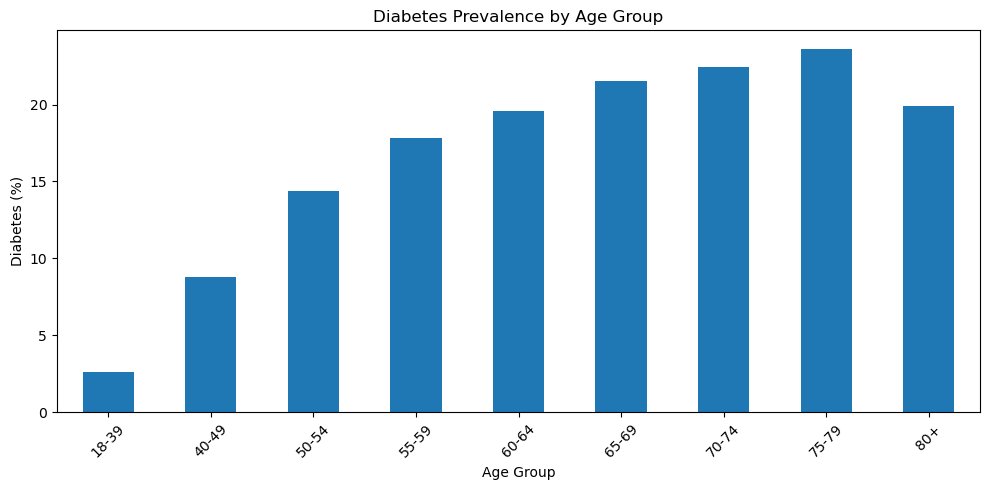

In [19]:

# Extract diabetes percentage for each detailed age group
diabetes_by_age = age_diabetes_detailed['Diabetes']

plt.figure(figsize=(10, 5))

diabetes_by_age.plot(kind='bar')

plt.title('Diabetes Prevalence by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Diabetes (%)')

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

### Conclusion: Age and Diabetes Status

The analysis shows a clear relationship between age and diabetes prevalence in the BRFSS 2025 sample. Diabetes prevalence increased from 3.65% among adults aged 18–44 to 16.01% among those aged 45–64 and 21.81% among those aged 65 and older.

The more detailed age-group analysis showed a similar pattern, with diabetes prevalence increasing steadily from 2.63% among adults aged 18–39 to a peak of 23.64% among those aged 75–79. The prevalence then decreased to 19.89% among respondents aged 80 and older.

Overall, these results suggest that age is an important factor associated with diabetes status in this sample. However, the analysis is descriptive, so other factors may also contribute to the observed differences across age groups.

### 3.2 Health and Physical Factors

In [20]:
# Check BMI variable
print(df['_BMI5'].describe())

print("\nMissing values:")
print(df['_BMI5'].isna().sum())

print("\nMissing percentage:")
print(round(df['_BMI5'].isna().mean() * 100, 2))

count    323596.000000
mean       2847.264790
std         653.000027
min        1202.000000
25%        2407.000000
50%        2741.000000
75%        3162.000000
max        9843.000000
Name: _BMI5, dtype: float64

Missing values:
32562

Missing percentage:
9.14


In [21]:
# Convert BRFSS BMI variable to standard BMI values
df['BMI'] = df['_BMI5'] / 100

print(df['BMI'].describe())

count    323596.000000
mean         28.472648
std           6.530000
min          12.020000
25%          24.070000
50%          27.410000
75%          31.620000
max          98.430000
Name: BMI, dtype: float64


In [22]:
# Create BMI categories for exploratory analysis
df['BMI_Category'] = pd.cut(
    df['BMI'],
    bins=[0, 18.5, 25, 30, float('inf')],
    labels=[
        'Underweight',
        'Normal weight',
        'Overweight',
        'Obesity'
    ],
    right=False
)

print(df['BMI_Category'].value_counts(dropna=False))

print("\nPercentage:")
print(
    df['BMI_Category']
    .value_counts(normalize=True, dropna=False) * 100
)

BMI_Category
Overweight       114838
Obesity          106934
Normal weight     96272
NaN               32562
Underweight        5552
Name: count, dtype: int64

Percentage:
BMI_Category
Overweight       32.243555
Obesity          30.024315
Normal weight    27.030700
NaN               9.142572
Underweight       1.558859
Name: proportion, dtype: float64


In [23]:
# Compare diabetes status by BMI category
bmi_diabetes = pd.crosstab(
    df['BMI_Category'],
    df['Diabetes_Status'],
    normalize='index'
) * 100

display(bmi_diabetes.round(2))

Diabetes_Status,Diabetes,No Diabetes,Prediabetes
BMI_Category,,,
Underweight,6.10,92.16,1.74
Normal weight,7.95,90.28,1.77
Overweight,13.67,83.73,2.60
Obesity,22.77,72.85,4.38


### BMI Analysis

The BRFSS BMI variable was converted to standard BMI values by dividing `_BMI5` by 100. About 9.14% of BMI values were missing.

Most respondents were overweight or obese:
- Overweight: 32.24%
- Obesity: 30.02%
- Normal weight: 27.03%
- Underweight: 1.56%

Diabetes prevalence increased as BMI increased:
- Underweight: 6.10%
- Normal weight: 7.95%
- Overweight: 13.67%
- Obesity: 22.77%

This shows a clear pattern in the sample: people in higher BMI categories had a higher proportion of diabetes. BMI will be kept as an important feature for later modeling.

In [24]:
# Check blood pressure variable
print(df['BPHIGH6'].value_counts(dropna=False).sort_index())

print("\nMissing values:")
print(df['BPHIGH6'].isna().sum())

print("\nMissing percentage:")
print(round(df['BPHIGH6'].isna().mean() * 100, 2))

BPHIGH6
1.0    147056
2.0      2810
3.0    198836
4.0      3208
7.0      1113
9.0       518
NaN      2617
Name: count, dtype: int64

Missing values:
2617

Missing percentage:
0.73


In [25]:
# Recode high blood pressure variable
bp_map = {
    1: 'High Blood Pressure',
    2: 'No High Blood Pressure',
    3: 'No High Blood Pressure',
    4: 'No High Blood Pressure'
}

df['HighBP'] = df['BPHIGH6'].map(bp_map)

print(df['HighBP'].value_counts(dropna=False))

print("\nPercentage:")
print(
    (df['HighBP']
     .value_counts(normalize=True, dropna=False) * 100)
     .round(2)
)

HighBP
No High Blood Pressure    204854
High Blood Pressure       147056
NaN                         4248
Name: count, dtype: int64

Percentage:
HighBP
No High Blood Pressure    57.52
High Blood Pressure       41.29
NaN                        1.19
Name: proportion, dtype: float64


In [26]:
# Compare diabetes status by high blood pressure
bp_diabetes = pd.crosstab(
    df['HighBP'],
    df['Diabetes_Status'],
    normalize='index'
) * 100

display(bp_diabetes.round(2))

Diabetes_Status,Diabetes,No Diabetes,Prediabetes
HighBP,,,
High Blood Pressure,25.70,70.22,4.08
No High Blood Pressure,6.78,91.21,2.00


### High Blood Pressure Analysis

After checking the CDC coding, `BPHIGH6` was recoded into two groups: High Blood Pressure and No High Blood Pressure. Unknown, refused, and missing responses were kept as missing values.

About 41.29% of respondents had high blood pressure.

Diabetes prevalence was much higher among people with high blood pressure:
- High Blood Pressure: 25.70%
- No High Blood Pressure: 6.78%

Prediabetes was also higher in the high blood pressure group (4.08% vs. 2.00%).

This shows a strong relationship between high blood pressure and diabetes status in this sample, so this variable will be kept for later modeling.

### 3.3 Lifestyle Factors

In [27]:
# Check smoking status variable
print(df['_SMOKER3'].value_counts(dropna=False).sort_index())

print("\nMissing values:")
print(df['_SMOKER3'].isna().sum())

print("\nMissing percentage:")
print(round(df['_SMOKER3'].isna().mean() * 100, 2))

_SMOKER3
1.0     24020
2.0     10454
3.0     96080
4.0    204951
9.0     20653
Name: count, dtype: int64

Missing values:
0

Missing percentage:
0.0


In [28]:
# Recode smoking status using CDC categories
smoker_map = {
    1: 'Current Smoker - Every Day',
    2: 'Current Smoker - Some Days',
    3: 'Former Smoker',
    4: 'Never Smoked'
}

df['Smoking_Status'] = df['_SMOKER3'].map(smoker_map)

print(df['Smoking_Status'].value_counts(dropna=False))

print("\nPercentage:")
print(
    (df['Smoking_Status']
     .value_counts(normalize=True, dropna=False) * 100)
     .round(2)
)

Smoking_Status
Never Smoked                  204951
Former Smoker                  96080
Current Smoker - Every Day     24020
NaN                            20653
Current Smoker - Some Days     10454
Name: count, dtype: int64

Percentage:
Smoking_Status
Never Smoked                  57.54
Former Smoker                 26.98
Current Smoker - Every Day     6.74
NaN                            5.80
Current Smoker - Some Days     2.94
Name: proportion, dtype: float64


In [29]:
# Compare diabetes status by smoking status
smoking_diabetes = pd.crosstab(
    df['Smoking_Status'],
    df['Diabetes_Status'],
    normalize='index'
) * 100

display(smoking_diabetes.round(2))

Diabetes_Status,Diabetes,No Diabetes,Prediabetes
Smoking_Status,,,
Current Smoker - Every Day,17.08,79.52,3.40
Current Smoker - Some Days,13.40,82.99,3.61
Former Smoker,18.02,78.87,3.11
Never Smoked,13.07,84.19,2.74


### Smoking Status Analysis

The CDC smoking variable `_SMOKER3` was recoded into four groups: current smoker every day, current smoker some days, former smoker, and never smoked. Unknown or missing responses were kept as missing values.

The diabetes rate was:
- Current smoker - every day: 17.08%
- Current smoker - some days: 13.40%
- Former smoker: 18.02%
- Never smoked: 13.07%

Former smokers had the highest diabetes rate, followed by daily smokers. People who never smoked had the lowest rate.

This pattern is not as simple as BMI or high blood pressure. Smoking status may also be related to age and other health conditions, so it will be kept for later modeling and further analysis.

In [30]:
# Check high cholesterol variable
print(df['_RFCHOL3'].value_counts(dropna=False).sort_index())

print("\nMissing values:")
print(df['_RFCHOL3'].isna().sum())

print("\nMissing percentage:")
print(round(df['_RFCHOL3'].isna().mean() * 100, 2))

_RFCHOL3
1.0    176467
2.0    134859
9.0      2869
NaN     41963
Name: count, dtype: int64

Missing values:
41963

Missing percentage:
11.78


In [31]:
# Recode high cholesterol variable
chol_map = {
    1: 'No High Cholesterol',
    2: 'High Cholesterol'
}

df['HighChol'] = df['_RFCHOL3'].map(chol_map)

print(df['HighChol'].value_counts(dropna=False))

print("\nPercentage:")
print(
    (df['HighChol']
     .value_counts(normalize=True, dropna=False) * 100)
     .round(2)
)

HighChol
No High Cholesterol    176467
High Cholesterol       134859
NaN                     44832
Name: count, dtype: int64

Percentage:
HighChol
No High Cholesterol    49.55
High Cholesterol       37.86
NaN                    12.59
Name: proportion, dtype: float64


In [32]:
# Compare diabetes status by cholesterol status
chol_diabetes = pd.crosstab(
    df['HighChol'],
    df['Diabetes_Status'],
    normalize='index'
) * 100

display(chol_diabetes.round(2))

Diabetes_Status,Diabetes,No Diabetes,Prediabetes
HighChol,,,
High Cholesterol,23.55,72.11,4.34
No High Cholesterol,9.93,88.01,2.06


### High Cholesterol Analysis

The CDC cholesterol variable `_RFCHOL3` was recoded into High Cholesterol and No High Cholesterol. Unknown, refused, and missing responses were kept as missing values.

About 37.86% of respondents had high cholesterol.

Diabetes prevalence was:
- High Cholesterol: 23.55%
- No High Cholesterol: 9.93%

Prediabetes was also higher in the high cholesterol group (4.34% vs. 2.06%).

This shows a clear relationship between high cholesterol and diabetes status in this sample. High cholesterol will be kept as a feature for later modeling.

In [33]:
# Check physical activity variable
print(df['_TOTINDA'].value_counts(dropna=False).sort_index())

print("\nMissing values:")
print(df['_TOTINDA'].isna().sum())

print("\nMissing percentage:")
print(round(df['_TOTINDA'].isna().mean() * 100, 2))

_TOTINDA
1.0    272901
2.0     82283
9.0       974
Name: count, dtype: int64

Missing values:
0

Missing percentage:
0.0


In [34]:
# Recode physical activity variable
activity_map = {
    1: 'Physically Active',
    2: 'No Physical Activity'
}

df['Physical_Activity'] = df['_TOTINDA'].map(activity_map)

print(df['Physical_Activity'].value_counts(dropna=False))

print("\nPercentage:")
print(
    (df['Physical_Activity']
     .value_counts(normalize=True, dropna=False) * 100)
     .round(2)
)

Physical_Activity
Physically Active       272901
No Physical Activity     82283
NaN                        974
Name: count, dtype: int64

Percentage:
Physical_Activity
Physically Active       76.62
No Physical Activity    23.10
NaN                      0.27
Name: proportion, dtype: float64


In [35]:
# Compare diabetes status by physical activity
activity_diabetes = pd.crosstab(
    df['Physical_Activity'],
    df['Diabetes_Status'],
    normalize='index'
) * 100

display(activity_diabetes.round(2))

Diabetes_Status,Diabetes,No Diabetes,Prediabetes
Physical_Activity,,,
No Physical Activity,23.93,72.56,3.51
Physically Active,11.89,85.42,2.69


### Physical Activity Analysis

The CDC physical activity variable `_TOTINDA` was recoded into Physically Active and No Physical Activity. Unknown or missing responses were kept as missing values.

About 76.62% of respondents were physically active, while 23.10% reported no physical activity.

Diabetes prevalence was:
- No Physical Activity: 23.93%
- Physically Active: 11.89%

Prediabetes was also slightly higher among people with no physical activity (3.51% vs. 2.69%).

This shows a clear relationship between physical activity and diabetes status in this sample. Physical activity will be kept as a feature for later modeling.

### 3.4 Socioeconomic Factors

In [36]:
# Check education variable
print(df['_EDUCAG'].value_counts(dropna=False).sort_index())

print("\nMissing values:")
print(df['_EDUCAG'].isna().sum())

print("\nMissing percentage:")
print(round(df['_EDUCAG'].isna().mean() * 100, 2))

_EDUCAG
1.0     20046
2.0     92036
3.0     93958
4.0    147966
9.0      2152
Name: count, dtype: int64

Missing values:
0

Missing percentage:
0.0


In [37]:
# Recode education variable using CDC categories
education_map = {
    1: 'Did Not Graduate High School',
    2: 'High School Graduate',
    3: 'Attended College or Technical School',
    4: 'College or Technical School Graduate'
}

df['Education'] = df['_EDUCAG'].map(education_map)

print(df['Education'].value_counts(dropna=False))

print("\nPercentage:")
print(
    (df['Education']
     .value_counts(normalize=True, dropna=False) * 100)
     .round(2)
)

Education
College or Technical School Graduate    147966
Attended College or Technical School     93958
High School Graduate                     92036
Did Not Graduate High School             20046
NaN                                       2152
Name: count, dtype: int64

Percentage:
Education
College or Technical School Graduate    41.55
Attended College or Technical School    26.38
High School Graduate                    25.84
Did Not Graduate High School             5.63
NaN                                      0.60
Name: proportion, dtype: float64


In [38]:
# Compare diabetes status by education level
education_diabetes = pd.crosstab(
    df['Education'],
    df['Diabetes_Status'],
    normalize='index'
) * 100

display(education_diabetes.round(2))

Diabetes_Status,Diabetes,No Diabetes,Prediabetes
Education,,,
Attended College or Technical School,16.61,80.34,3.05
College or Technical School Graduate,11.42,86.19,2.39
Did Not Graduate High School,21.82,73.34,4.83
High School Graduate,16.51,80.39,3.10


### Education Analysis

The CDC education variable `_EDUCAG` was recoded into four education groups. Unknown or missing responses were kept as missing values.

Diabetes prevalence was:
- Did Not Graduate High School: 21.82%
- High School Graduate: 16.51%
- Attended College or Technical School: 16.61%
- College or Technical School Graduate: 11.42%

Overall, respondents with higher education levels tended to have lower diabetes prevalence. The college or technical school graduate group had the lowest diabetes rate.

Education will be kept as a socioeconomic feature for later modeling.

In [39]:
# Check income variable
print(df['_INCOMG1'].value_counts(dropna=False).sort_index())

print("\nMissing values:")
print(df['_INCOMG1'].isna().sum())

print("\nMissing percentage:")
print(round(df['_INCOMG1'].isna().mean() * 100, 2))

_INCOMG1
1.0    15694
2.0    25542
3.0    31691
4.0    37977
5.0    86261
6.0    64577
7.0    23366
9.0    71050
Name: count, dtype: int64

Missing values:
0

Missing percentage:
0.0


In [40]:
# Recode income variable using CDC categories
income_map = {
    1: 'Less than $15,000',
    2: '$15,000 to < $25,000',
    3: '$25,000 to < $35,000',
    4: '$35,000 to < $50,000',
    5: '$50,000 to < $100,000',
    6: '$100,000 to < $200,000',
    7: '$200,000 or more'
}

df['Income_Group'] = df['_INCOMG1'].map(income_map)

print(df['Income_Group'].value_counts(dropna=False))

print("\nPercentage:")
print(
    (df['Income_Group']
     .value_counts(normalize=True, dropna=False) * 100)
     .round(2)
)

Income_Group
$50,000 to < $100,000     86261
NaN                       71050
$100,000 to < $200,000    64577
$35,000 to < $50,000      37977
$25,000 to < $35,000      31691
$15,000 to < $25,000      25542
$200,000 or more          23366
Less than $15,000         15694
Name: count, dtype: int64

Percentage:
Income_Group
$50,000 to < $100,000     24.22
NaN                       19.95
$100,000 to < $200,000    18.13
$35,000 to < $50,000      10.66
$25,000 to < $35,000       8.90
$15,000 to < $25,000       7.17
$200,000 or more           6.56
Less than $15,000          4.41
Name: proportion, dtype: float64


In [41]:
# Compare diabetes status by income group
income_diabetes = pd.crosstab(
    df['Income_Group'],
    df['Diabetes_Status'],
    normalize='index'
) * 100

display(income_diabetes.round(2))

Diabetes_Status,Diabetes,No Diabetes,Prediabetes
Income_Group,,,
"$100,000 to < $200,000",10.10,87.81,2.09
"$15,000 to < $25,000",23.35,72.60,4.05
"$200,000 or more",6.49,91.83,1.68
"$25,000 to < $35,000",19.19,77.39,3.42
"$35,000 to < $50,000",16.97,79.75,3.28
"$50,000 to < $100,000",13.89,83.40,2.71
"Less than $15,000",22.40,73.10,4.50


### Income Analysis

The CDC income variable `_INCOMG1` was recoded into seven income groups. Unknown, refused, and missing responses were kept as missing values.

Diabetes prevalence generally decreased as income increased. It was above 22% in the two lowest income groups and decreased to 6.49% among respondents with household income of $200,000 or more.

This shows a clear relationship between income and diabetes status in this sample. Income will be kept as a socioeconomic feature for later modeling.

### 3.5 Race and Ethnicity

In [42]:
# Check race/ethnicity variable
print(df['_RACEPRV'].value_counts(dropna=False).sort_index())

print("\nMissing values:")
print(df['_RACEPRV'].isna().sum())

print("\nMissing percentage:")
print(round(df['_RACEPRV'].isna().mean() * 100, 2))

_RACEPRV
1.0    265193
2.0     26308
3.0      5193
4.0     10075
5.0      2247
6.0      3114
7.0      8729
8.0     35296
NaN         3
Name: count, dtype: int64

Missing values:
3

Missing percentage:
0.0


In [43]:
# Recode race/ethnicity using CDC categories
race_map = {
    1: 'White, Non-Hispanic',
    2: 'Black, Non-Hispanic',
    3: 'American Indian/Alaska Native, Non-Hispanic',
    4: 'Asian, Non-Hispanic',
    5: 'Native Hawaiian/Pacific Islander, Non-Hispanic',
    6: 'Other Race, Non-Hispanic',
    7: 'Multiracial, Non-Hispanic',
    8: 'Hispanic'
}

df['Race_Ethnicity'] = df['_RACEPRV'].map(race_map)

print(df['Race_Ethnicity'].value_counts(dropna=False))

print("\nPercentage:")
print(
    (df['Race_Ethnicity']
     .value_counts(normalize=True, dropna=False) * 100)
     .round(2)
)

Race_Ethnicity
White, Non-Hispanic                               265193
Hispanic                                           35296
Black, Non-Hispanic                                26308
Asian, Non-Hispanic                                10075
Multiracial, Non-Hispanic                           8729
American Indian/Alaska Native, Non-Hispanic         5193
Other Race, Non-Hispanic                            3114
Native Hawaiian/Pacific Islander, Non-Hispanic      2247
NaN                                                    3
Name: count, dtype: int64

Percentage:
Race_Ethnicity
White, Non-Hispanic                               74.46
Hispanic                                           9.91
Black, Non-Hispanic                                7.39
Asian, Non-Hispanic                                2.83
Multiracial, Non-Hispanic                          2.45
American Indian/Alaska Native, Non-Hispanic        1.46
Other Race, Non-Hispanic                           0.87
Native Hawaiian/Pacific Is

In [44]:
# Compare diabetes status by race/ethnicity
race_diabetes = pd.crosstab(
    df['Race_Ethnicity'],
    df['Diabetes_Status'],
    normalize='index'
) * 100

display(race_diabetes.round(2))

Diabetes_Status,Diabetes,No Diabetes,Prediabetes
Race_Ethnicity,,,
"American Indian/Alaska Native, Non-Hispanic",20.67,75.63,3.70
"Asian, Non-Hispanic",11.60,83.62,4.79
"Black, Non-Hispanic",20.60,75.31,4.09
Hispanic,13.83,81.69,4.48
"Multiracial, Non-Hispanic",13.94,81.82,4.24
"Native Hawaiian/Pacific Islander, Non-Hispanic",18.99,75.51,5.50
"Other Race, Non-Hispanic",16.33,80.65,3.02
"White, Non-Hispanic",14.20,83.41,2.40


### Race/Ethnicity Analysis

The CDC `_RACEPRV` variable was recoded into eight race/ethnicity groups.

Diabetes prevalence differed across groups. The highest rates were seen among American Indian/Alaska Native respondents (20.67%) and Black respondents (20.60%). Asian respondents had the lowest diabetes rate at 11.60%.

These differences show that race/ethnicity is related to diabetes status in this sample. However, the groups also differ in age, income, and other factors, so these results are descriptive only.

Race/ethnicity will be kept as a feature for later modeling.

### 3.6 Diet Variables

In [45]:
# Check total fruit intake variable
print(df['_FRUTSU1'].describe())

print("\nMissing values:")
print(df['_FRUTSU1'].isna().sum())

print("\nMissing percentage:")
print(round(df['_FRUTSU1'].isna().mean() * 100, 2))

count    3.097170e+05
mean     1.527271e+02
std      4.877094e+02
min      5.397605e-79
25%      5.000000e+01
50%      1.000000e+02
75%      2.000000e+02
max      1.980000e+04
Name: _FRUTSU1, dtype: float64

Missing values:
46441

Missing percentage:
13.04


In [46]:
# Convert fruit intake to times per day
df['Fruit_Per_Day'] = df['_FRUTSU1'] / 100

print(df['Fruit_Per_Day'].describe())

count    3.097170e+05
mean     1.527271e+00
std      4.877094e+00
min      5.397605e-81
25%      5.000000e-01
50%      1.000000e+00
75%      2.000000e+00
max      1.980000e+02
Name: Fruit_Per_Day, dtype: float64


In [47]:
# Create simple fruit intake groups
df['Fruit_Intake_Group'] = pd.cut(
    df['Fruit_Per_Day'],
    bins=[-0.01, 1, float('inf')],
    labels=[
        'Less Than 1 Time Per Day',
        '1 or More Times Per Day'
    ],
    right=False
)

print(df['Fruit_Intake_Group'].value_counts(dropna=False))

fruit_diabetes = pd.crosstab(
    df['Fruit_Intake_Group'],
    df['Diabetes_Status'],
    normalize='index'
) * 100

display(fruit_diabetes.round(2))

Fruit_Intake_Group
1 or More Times Per Day     183187
Less Than 1 Time Per Day    126530
NaN                          46441
Name: count, dtype: int64


Diabetes_Status,Diabetes,No Diabetes,Prediabetes
Fruit_Intake_Group,,,
Less Than 1 Time Per Day,15.90,81.08,3.02
1 or More Times Per Day,13.93,83.20,2.87


### Fruit Intake Analysis

The CDC `_FRUTSU1` variable was converted to estimated fruit intake per day and grouped into less than 1 time per day and 1 or more times per day.

Diabetes prevalence was:
- Less than 1 time per day: 15.90%
- 1 or more times per day: 13.93%

The difference was relatively small compared with factors such as BMI or high blood pressure. Fruit intake will still be kept as a lifestyle feature for later modeling.

In [48]:
# Check total vegetable intake variable
print(df['_VEGESU1'].describe())

print("\nMissing values:")
print(df['_VEGESU1'].isna().sum())

print("\nMissing percentage:")
print(round(df['_VEGESU1'].isna().mean() * 100, 2))

count    3.026310e+05
mean     2.280403e+02
std      7.478239e+02
min      5.397605e-79
25%      1.040000e+02
50%      1.570000e+02
75%      2.240000e+02
max      3.960000e+04
Name: _VEGESU1, dtype: float64

Missing values:
53527

Missing percentage:
15.03


In [49]:
# Convert vegetable intake to times per day
df['Vegetable_Per_Day'] = df['_VEGESU1'] / 100

print(df['Vegetable_Per_Day'].describe())

count    3.026310e+05
mean     2.280403e+00
std      7.478239e+00
min      5.397605e-81
25%      1.040000e+00
50%      1.570000e+00
75%      2.240000e+00
max      3.960000e+02
Name: Vegetable_Per_Day, dtype: float64


In [50]:
# Create simple vegetable intake groups
df['Vegetable_Intake_Group'] = pd.cut(
    df['Vegetable_Per_Day'],
    bins=[-0.01, 1, float('inf')],
    labels=[
        'Less Than 1 Time Per Day',
        '1 or More Times Per Day'
    ],
    right=False
)

print(df['Vegetable_Intake_Group'].value_counts(dropna=False))

vegetable_diabetes = pd.crosstab(
    df['Vegetable_Intake_Group'],
    df['Diabetes_Status'],
    normalize='index'
) * 100

display(vegetable_diabetes.round(2))

Vegetable_Intake_Group
1 or More Times Per Day     236686
Less Than 1 Time Per Day     65945
NaN                          53527
Name: count, dtype: int64


Diabetes_Status,Diabetes,No Diabetes,Prediabetes
Vegetable_Intake_Group,,,
Less Than 1 Time Per Day,17.54,79.10,3.37
1 or More Times Per Day,13.93,83.26,2.80


### Vegetable Intake Analysis

The CDC `_VEGESU1` variable was converted to estimated vegetable intake per day and grouped into less than 1 time per day and 1 or more times per day.

Diabetes prevalence was:
- Less than 1 time per day: 17.54%
- 1 or more times per day: 13.93%

The difference was larger than what was seen for fruit intake. Respondents with lower vegetable intake had a higher diabetes rate in this sample.

Vegetable intake will be kept as a lifestyle feature for later modeling.

### 3.7 General Health

In [51]:
# Check general health variable
print(df['GENHLTH'].value_counts(dropna=False).sort_index())

print("\nMissing values:")
print(df['GENHLTH'].isna().sum())

print("\nMissing percentage:")
print(round(df['GENHLTH'].isna().mean() * 100, 2))

GENHLTH
1.0     48860
2.0    114578
3.0    120795
4.0     53372
5.0     17589
7.0       685
9.0       274
NaN         5
Name: count, dtype: int64

Missing values:
5

Missing percentage:
0.0


In [52]:
# Recode general health variable
general_health_map = {
    1: 'Excellent',
    2: 'Very Good',
    3: 'Good',
    4: 'Fair',
    5: 'Poor'
}

df['General_Health'] = df['GENHLTH'].map(general_health_map)

print(df['General_Health'].value_counts(dropna=False))

print("\nPercentage:")
print(
    (df['General_Health']
     .value_counts(normalize=True, dropna=False) * 100)
     .round(2)
)

General_Health
Good         120795
Very Good    114578
Fair          53372
Excellent     48860
Poor          17589
NaN             964
Name: count, dtype: int64

Percentage:
General_Health
Good         33.92
Very Good    32.17
Fair         14.99
Excellent    13.72
Poor          4.94
NaN           0.27
Name: proportion, dtype: float64


In [53]:
# Compare diabetes status by general health
general_health_diabetes = pd.crosstab(
    df['General_Health'],
    df['Diabetes_Status'],
    normalize='index'
) * 100

display(general_health_diabetes.round(2))

Diabetes_Status,Diabetes,No Diabetes,Prediabetes
General_Health,,,
Excellent,3.32,95.50,1.18
Fair,27.83,67.43,4.74
Good,16.80,79.84,3.36
Poor,35.54,60.30,4.16
Very Good,8.00,89.97,2.03


### General Health Analysis

The `GENHLTH` variable was recoded into five health status groups: Excellent, Very Good, Good, Fair, and Poor.

Diabetes prevalence increased as self-reported health became worse:
- Excellent: 3.32%
- Very Good: 8.00%
- Good: 16.80%
- Fair: 27.83%
- Poor: 35.54%

General health is a complex variable and should be interpreted carefully. 

Poor general health may be related to diabetes, but it may also be a result of diabetes or other chronic health conditions. 

For this reason, models with and without this variable may be compared later.

## 4. Modeling Dataset Preparation

In [54]:
# Current cleaned features prepared for modeling
current_features = [
    'Diabetes_Status',
    'Age',
    'Sex',
    'BMI',
    'HighBP',
    'Smoking_Status',
    'HighChol',
    'Physical_Activity',
    'Education',
    'Income_Group',
    'Race_Ethnicity',
    'Fruit_Per_Day',
    'Vegetable_Per_Day',
    'General_Health'
]

feature_summary = df[current_features].copy()

print("Shape:")
print(feature_summary.shape)

print("\nFirst 5 rows:")
display(feature_summary.head())


Shape:
(356158, 14)

First 5 rows:


,Diabetes_Status,Age,Sex,BMI,HighBP,Smoking_Status,HighChol,Physical_Activity,Education,Income_Group,Race_Ethnicity,Fruit_Per_Day,Vegetable_Per_Day,General_Health
0,No Diabetes,71.0,Female,30.79,High Blood Pressure,Never Smoked,No High Cholesterol,Physically Active,Attended College or Technical School,"$35,000 to < $50,000","Black, Non-Hispanic",1.00,1.30,Good
1,Diabetes,80.0,Female,19.66,High Blood Pressure,Never Smoked,High Cholesterol,Physically Active,Attended College or Technical School,NaN,"White, Non-Hispanic",1.07,1.45,Good
2,Diabetes,68.0,Female,33.20,High Blood Pressure,Never Smoked,High Cholesterol,No Physical Activity,High School Graduate,NaN,"White, Non-Hispanic",0.72,1.44,Fair
3,Diabetes,80.0,Male,29.80,High Blood Pressure,Never Smoked,No High Cholesterol,No Physical Activity,High School Graduate,NaN,"White, Non-Hispanic",3.00,0.63,Fair
4,No Diabetes,64.0,Male,28.46,No High Blood Pressure,Never Smoked,High Cholesterol,Physically Active,Attended College or Technical School,"$50,000 to < $100,000","White, Non-Hispanic",1.00,7.00,Good


In [55]:
feature_summary.to_csv('feature.csv', index=False)

### 4.1 Missing Data Review

In [56]:
# Check missing values for current modeling features
missing_summary = pd.DataFrame({
    'Missing_Count': feature_summary.isna().sum(),
    'Missing_Percentage': (
        feature_summary.isna().mean() * 100
    ).round(2)
})

missing_summary = missing_summary.sort_values(
    'Missing_Percentage',
    ascending=False
)

display(missing_summary)

,Missing_Count,Missing_Percentage
Income_Group,71050,19.95
Vegetable_Per_Day,53527,15.03
Fruit_Per_Day,46441,13.04
HighChol,44832,12.59
BMI,32562,9.14
Smoking_Status,20653,5.80
HighBP,4248,1.19
Diabetes_Status,3453,0.97
Education,2152,0.60
Physical_Activity,974,0.27


In [57]:
# Check how many rows would remain if all current features had to be complete
complete_case_count = feature_summary.dropna().shape[0]
total_count = feature_summary.shape[0]

print("Total rows:", total_count)
print("Complete rows:", complete_case_count)
print("Rows removed:", total_count - complete_case_count)
print(
    "Complete-case percentage:",
    round(complete_case_count / total_count * 100, 2)
)

Total rows: 356158
Complete rows: 212698
Rows removed: 143460
Complete-case percentage: 59.72


In [58]:
# Count missing features per row
missing_per_row = feature_summary.isna().sum(axis=1)

print(missing_per_row.value_counts().sort_index())

print("\nPercentage:")
print(
    (missing_per_row.value_counts(normalize=True)
     .sort_index() * 100)
     .round(2)
)

0     212698
1      77134
2      31176
3      14070
4       9332
5       9220
6       2144
7        288
8         47
9         21
10        18
11        10
Name: count, dtype: int64

Percentage:
0     59.72
1     21.66
2      8.75
3      3.95
4      2.62
5      2.59
6      0.60
7      0.08
8      0.01
9      0.01
10     0.01
11     0.00
Name: proportion, dtype: float64


### Conclusion

If all rows with any missing value were removed, only 212,698 of 356,158 records would remain (59.72%). This would remove about 40% of the dataset.

Most incomplete records are missing only one or two features. Because of this, complete-case deletion would remove too much useful data.

Missing values will be handled during preprocessing instead of dropping all incomplete rows.

## 5. Preprocessing and Train/Test Preparation

In [59]:
# Create modeling dataframe
model_df = feature_summary.dropna(subset=['Diabetes_Status']).copy()

print("Original rows:", feature_summary.shape[0])
print("Rows after removing missing target:", model_df.shape[0])
print("Rows removed:", feature_summary.shape[0] - model_df.shape[0])

print("\nTarget distribution:")
print(model_df['Diabetes_Status'].value_counts())

print("\nTarget percentage:")
print(
    (model_df['Diabetes_Status']
     .value_counts(normalize=True) * 100)
     .round(2)
)

Original rows: 356158
Rows after removing missing target: 352705
Rows removed: 3453

Target distribution:
Diabetes_Status
No Diabetes    290712
Diabetes        51827
Prediabetes     10166
Name: count, dtype: int64

Target percentage:
Diabetes_Status
No Diabetes    82.42
Diabetes       14.69
Prediabetes     2.88
Name: proportion, dtype: float64


In [60]:
# Separate predictors and target
X = model_df.drop(columns='Diabetes_Status')
y = model_df['Diabetes_Status']

# Numeric features
numeric_features = [
    'Age',
    'BMI',
    'Fruit_Per_Day',
    'Vegetable_Per_Day'
]

# Categorical features
categorical_features = [
    'Sex',
    'HighBP',
    'Smoking_Status',
    'HighChol',
    'Physical_Activity',
    'Education',
    'Income_Group',
    'Race_Ethnicity',
    'General_Health'
]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nNumeric features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

X shape: (352705, 13)
y shape: (352705,)

Numeric features:
['Age', 'BMI', 'Fruit_Per_Day', 'Vegetable_Per_Day']

Categorical features:
['Sex', 'HighBP', 'Smoking_Status', 'HighChol', 'Physical_Activity', 'Education', 'Income_Group', 'Race_Ethnicity', 'General_Health']


In [61]:
# Check that all predictors are accounted for
selected_features = numeric_features + categorical_features

print("Number of predictors in X:", X.shape[1])
print("Number of listed predictors:", len(selected_features))

print("\nPredictors not included in feature lists:")
print(set(X.columns) - set(selected_features))

print("\nListed features not found in X:")
print(set(selected_features) - set(X.columns))

Number of predictors in X: 13
Number of listed predictors: 13

Predictors not included in feature lists:
set()

Listed features not found in X:
set()


### 5.1 Train/Test Split

In [62]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

print("\nTraining target distribution (%):")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTesting target distribution (%):")
print((y_test.value_counts(normalize=True) * 100).round(2))

X_train shape: (282164, 13)
X_test shape: (70541, 13)
y_train shape: (282164,)
y_test shape: (70541,)

Training target distribution (%):
Diabetes_Status
No Diabetes    82.42
Diabetes       14.69
Prediabetes     2.88
Name: proportion, dtype: float64

Testing target distribution (%):
Diabetes_Status
No Diabetes    82.42
Diabetes       14.70
Prediabetes     2.88
Name: proportion, dtype: float64


### 5.2 Preprocessing Pipeline

In [63]:
# Numeric preprocessing:
# fill missing values with the median and scale the values
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing:
# fill missing values with the most frequent category
# and convert categories into numeric dummy variables
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# Apply the correct preprocessing to each feature type
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print(preprocessor)

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['Age', 'BMI', 'Fruit_Per_Day',
                                  'Vegetable_Per_Day']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['Sex', 'HighBP', 'Smoking_Status', 'HighChol',
                                  'Physical_Activity', 'Education',
                                  'Income_Group', 'Race_Ethnicity',
                                  'General_Healt

### Preprocessing Setup

The dataset was split into training and testing sets using stratified sampling to preserve the original diabetes class distribution.

A preprocessing pipeline was then prepared:
- Numeric features: median imputation and standardization
- Categorical features: most frequent imputation and one-hot encoding

The preprocessing steps will be applied to the training data before model development.

## 5. Preprocessing and Train/Test Preparation

### 5.3 Preprocessing Validation

In [67]:
# Fit the preprocessing pipeline using training data only
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the same fitted preprocessing to the test data
X_test_processed = preprocessor.transform(X_test)

# Check the transformed shapes
print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)

print("\nOriginal test shape:", X_test.shape)
print("Processed test shape:", X_test_processed.shape)

# Check for missing values after preprocessing
train_missing = pd.isna(X_train_processed).sum()
test_missing = pd.isna(X_test_processed).sum()

print("Missing values after preprocessing:")
print("Training data:", train_missing)
print("Test data:", test_missing)

Original training shape: (282164, 13)
Processed training shape: (282164, 40)

Original test shape: (70541, 13)
Processed test shape: (70541, 40)
Missing values after preprocessing:
Training data: 0
Test data: 0


## 5.4 Class Distribution Before Modeling

In [68]:
# Check class distribution in the training data
class_counts = y_train.value_counts()
class_percentages = y_train.value_counts(normalize=True) * 100

class_distribution = pd.DataFrame({
    'Count': class_counts,
    'Percentage': class_percentages.round(2)
})

display(class_distribution)

,Count,Percentage
Diabetes_Status,,
No Diabetes,232570,82.42
Diabetes,41461,14.69
Prediabetes,8133,2.88


Conclusion:
The training data is highly imbalanced. Prediabetes represents only 2.88% of the training set, compared with 82.42% for No Diabetes and 14.69% for Diabetes. Therefore, model evaluation should not rely on accuracy alone. Class-level recall and F1-score, especially for Prediabetes, will be important in the next stage.